In [1]:

import os
import json
import time
import joblib
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.kernel_approximation import Nystroem
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

INPUT_DIR = Path("/kaggle/input")

metadata_files = [
    p for p in INPUT_DIR.rglob("metadata.json")
    if (p.parent / "X_train_scaled.npy").exists()
]

if not metadata_files:
    raise FileNotFoundError(
        "Processed dataset not found. "
        "Please add Notebook 00 output as input."
    )

DATA_DIR = metadata_files[0].parent

print("Dataset directory:", DATA_DIR)

print("\nAvailable files:")
for file in sorted(DATA_DIR.iterdir()):
    print(file.name)


Dataset directory: /kaggle/input/notebooks/ahmadlmomani/00-dry-bean-eda-preprocessing/dry_bean_processed

Available files:
X_test_scaled.csv
X_test_scaled.npy
X_train_scaled.csv
X_train_scaled.npy
imputer.pkl
label_encoder.pkl
metadata.json
scaler.pkl
y_test.csv
y_test.npy
y_train.csv
y_train.npy


In [3]:

X_train = np.load(DATA_DIR / "X_train_scaled.npy")
X_test = np.load(DATA_DIR / "X_test_scaled.npy")

y_train = np.load(DATA_DIR / "y_train.npy")
y_test = np.load(DATA_DIR / "y_test.npy")

with open(DATA_DIR / "metadata.json", "r") as f:
    metadata = json.load(f)

class_names = metadata["classes"]
classes = np.unique(y_train)

print("Dataset loaded successfully!")

print("\nTraining Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Labels:", y_train.shape)
print("Testing Labels:", y_test.shape)

print("\nClasses:", class_names)
print("Number of Classes:", len(classes))


Dataset loaded successfully!

Training Features: (10834, 16)
Testing Features: (2709, 16)
Training Labels: (10834,)
Testing Labels: (2709,)

Classes: ['BARBUNYA', 'BOMBAY', 'CALI', 'DERMASON', 'HOROZ', 'SEKER', 'SIRA']
Number of Classes: 7


In [4]:

KERNELS = {
    "Linear": {
        "kernel": "linear"
    },
    "Polynomial": {
        "kernel": "poly",
        "degree": 3,
        "coef0": 0
    },
    "RBF": {
        "kernel": "rbf"
    },
    "Sigmoid": {
        "kernel": "sigmoid",
        "coef0": 0
    }
}
GD_CONFIG = {
    "learning_rate": 0.05,
    "epochs": 500,
    "regularization": 0.001,
    "n_components": 300
}

print("GD Configuration:")
print(GD_CONFIG)

print("\nKernels:")
for name, params in KERNELS.items():
    print(name, params)


GD Configuration:
{'learning_rate': 0.05, 'epochs': 500, 'regularization': 0.001, 'n_components': 300}

Kernels:
Linear {'kernel': 'linear'}
Polynomial {'kernel': 'poly', 'degree': 3, 'coef0': 0}
RBF {'kernel': 'rbf'}
Sigmoid {'kernel': 'sigmoid', 'coef0': 0}


In [5]:

def train_svm_gd(
    X,
    y,
    learning_rate=0.05,
    epochs=500,
    reg_strength=0.001
):
    n_samples, n_features = X.shape

    classes = np.unique(y)
    n_classes = len(classes)

    # One-vs-Rest labels: +1 for target class, -1 otherwise
    Y = np.where(
        y[:, None] == classes[None, :],
        1.0,
        -1.0
    )

    # Initialize weights
    W = np.zeros((n_features, n_classes))

    loss_history = []

    for epoch in range(epochs):

        # Calculate decision scores
        scores = X @ W

        # Calculate margins
        margins = 1 - Y * scores

        # Hinge loss
        hinge_loss = np.maximum(0, margins)

        # Objective function
        loss = (
            np.sum(np.mean(hinge_loss, axis=0))
            + 0.5 * reg_strength * np.sum(W ** 2)
        )

        loss_history.append(loss)

        # Subgradient of hinge loss
        active = (margins > 0).astype(float)

        gradient = (
            -(X.T @ (Y * active)) / n_samples
            + reg_strength * W
        )

        # Full-batch Gradient Descent update
        W -= learning_rate * gradient

    return W, loss_history, classes


print("Multiclass SVM with GD implemented successfully!")


Multiclass SVM with GD implemented successfully!


In [6]:

gd_models = {}
gd_results = []

for kernel_name, kernel_params in KERNELS.items():

    print("\n" + "=" * 60)
    print(f"Training GD with {kernel_name} Kernel")
    print("=" * 60)

    start_time = time.time()

    # Kernel approximation
    feature_map = Nystroem(
        n_components=GD_CONFIG["n_components"],
        random_state=RANDOM_STATE,
        gamma=1.0 / X_train.shape[1],
        **kernel_params
    )

    Z_train = feature_map.fit_transform(X_train)
    Z_test = feature_map.transform(X_test)

    # Train using Gradient Descent
    W, loss_history, trained_classes = train_svm_gd(
        Z_train,
        y_train,
        learning_rate=GD_CONFIG["learning_rate"],
        epochs=GD_CONFIG["epochs"],
        reg_strength=GD_CONFIG["regularization"]
    )

    # Predictions
    train_scores = Z_train @ W
    test_scores = Z_test @ W

    y_pred = trained_classes[np.argmax(test_scores, axis=1)]

    training_time = time.time() - start_time

    # Store model components
    gd_models[kernel_name] = {
        "feature_map": feature_map,
        "weights": W,
        "classes": trained_classes,
        "loss_history": loss_history
    }

    # Evaluation
    gd_results.append({
        "Kernel": kernel_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred,
            average="macro",
            zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred,
            average="macro",
            zero_division=0
        ),
        "Macro F1": f1_score(
            y_test, y_pred,
            average="macro",
            zero_division=0
        ),
        "Weighted F1": f1_score(
            y_test, y_pred,
            average="weighted",
            zero_division=0
        ),
        "Final Loss": loss_history[-1],
        "Training Time": training_time
    })

    print("Training completed!")
    print(f"Final Loss: {loss_history[-1]:.4f}")
    print(f"Training Time: {training_time:.2f} seconds")

print("\nAll GD experiments completed!")



Training GD with Linear Kernel
Training completed!
Final Loss: 4.0972
Training Time: 5.61 seconds

Training GD with Polynomial Kernel
Training completed!
Final Loss: 4.8289
Training Time: 5.58 seconds

Training GD with RBF Kernel
Training completed!
Final Loss: 1.3016
Training Time: 5.56 seconds

Training GD with Sigmoid Kernel
Training completed!
Final Loss: 4.3338
Training Time: 5.64 seconds

All GD experiments completed!


In [7]:

gd_results_df = pd.DataFrame(gd_results)

gd_results_df = gd_results_df.sort_values(
    by="Macro F1",
    ascending=False
).reset_index(drop=True)

print("Gradient Descent Results")

display(
    gd_results_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "Macro F1": "{:.4f}",
        "Weighted F1": "{:.4f}",
        "Final Loss": "{:.4f}",
        "Training Time": "{:.2f}"
    })
)


Gradient Descent Results


,Kernel,Accuracy,Precision,Recall,Macro F1,Weighted F1,Final Loss,Training Time
0,RBF,0.8571,0.8957,0.8713,0.8730,0.8496,1.3016,5.56
1,Linear,0.7992,0.7660,0.8197,0.7773,0.7983,4.0972,5.61
2,Sigmoid,0.7652,0.8347,0.7984,0.7596,0.7190,4.3338,5.64
3,Polynomial,0.7542,0.8162,0.8003,0.7337,0.6865,4.8289,5.58


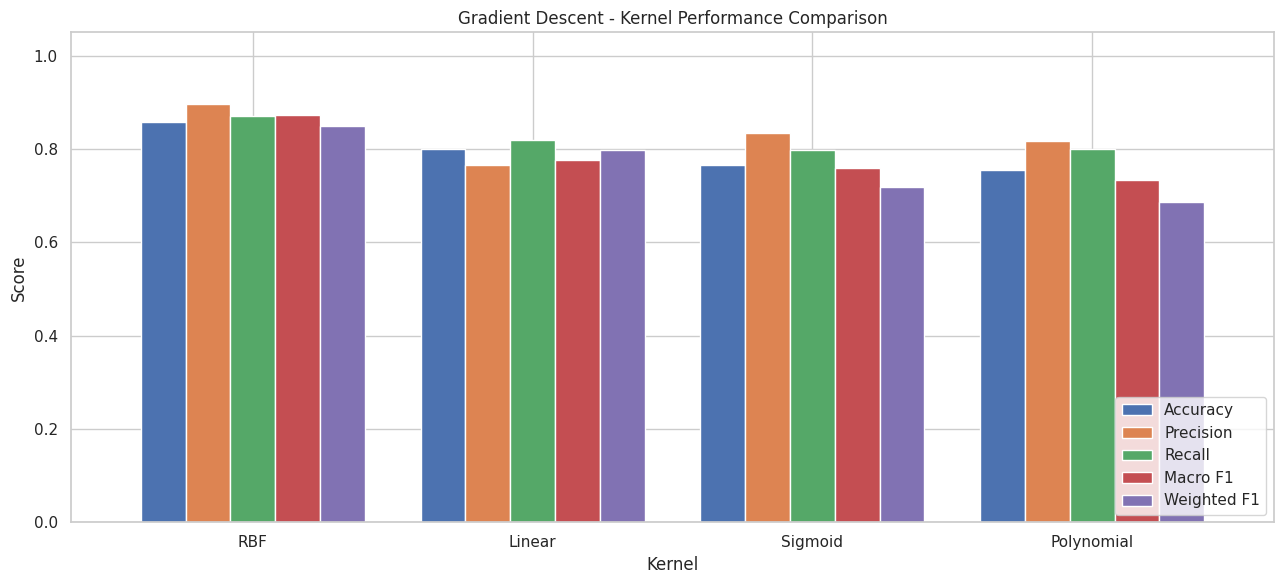

In [8]:

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "Macro F1",
    "Weighted F1"
]

ax = gd_results_df.set_index("Kernel")[metrics].plot(
    kind="bar",
    figsize=(13, 6),
    width=0.8
)

plt.title("Gradient Descent - Kernel Performance Comparison")
plt.xlabel("Kernel")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(loc="lower right")

plt.tight_layout()
plt.show()


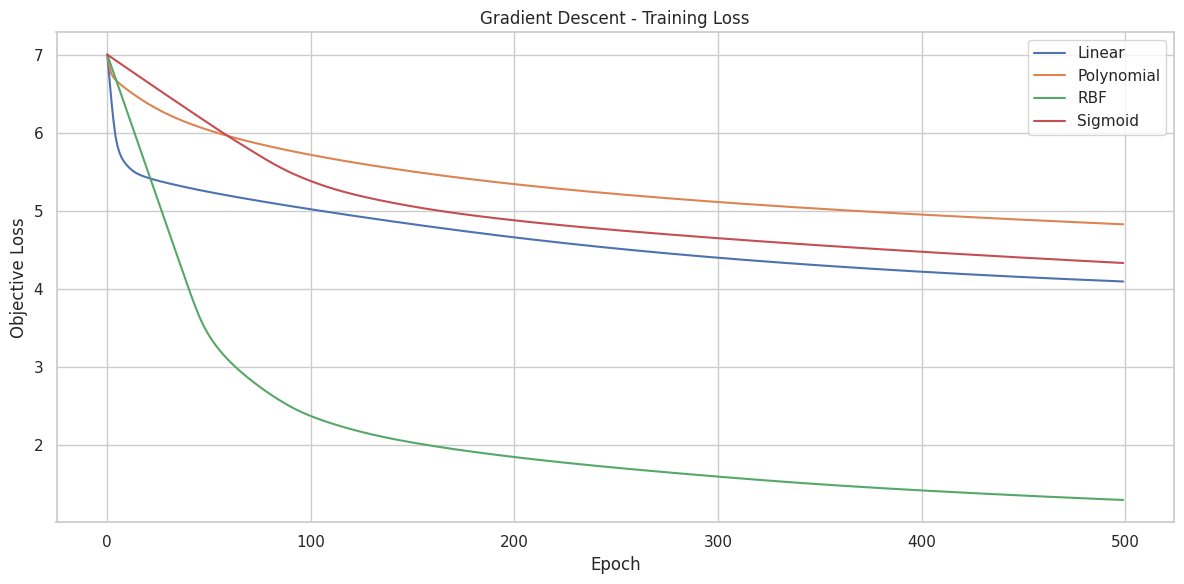

In [9]:

plt.figure(figsize=(12, 6))

for kernel_name, model_data in gd_models.items():

    plt.plot(
        model_data["loss_history"],
        label=kernel_name
    )

plt.title("Gradient Descent - Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Objective Loss")
plt.legend()
plt.tight_layout()
plt.show()


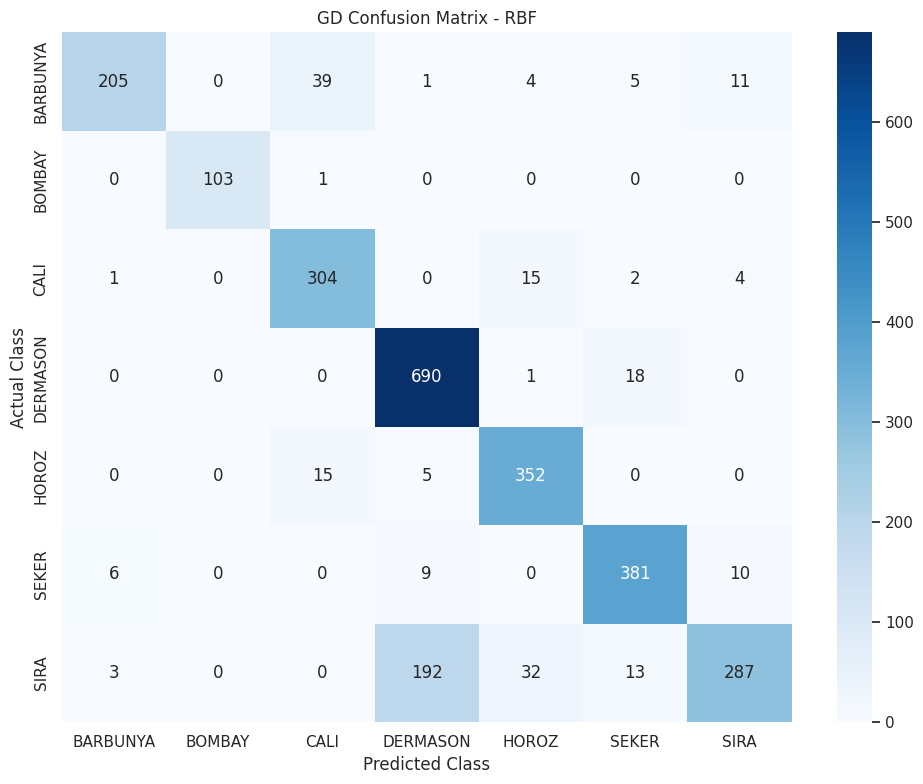

Best Kernel: RBF


In [10]:

best_kernel = gd_results_df.iloc[0]["Kernel"]

best_model = gd_models[best_kernel]

Z_test_best = best_model["feature_map"].transform(X_test)

y_pred = best_model["classes"][
    np.argmax(Z_test_best @ best_model["weights"], axis=1)
]

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title(f"GD Confusion Matrix - {best_kernel}")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()
plt.show()

print("Best Kernel:", best_kernel)


In [11]:

print(f"Classification Report - GD with {best_kernel} Kernel")
print("=" * 60)

print(
    classification_report(
        y_test,
        y_pred,
        labels=classes,
        target_names=class_names,
        zero_division=0
    )
)


Classification Report - GD with RBF Kernel
              precision    recall  f1-score   support

    BARBUNYA       0.95      0.77      0.85       265
      BOMBAY       1.00      0.99      1.00       104
        CALI       0.85      0.93      0.89       326
    DERMASON       0.77      0.97      0.86       709
       HOROZ       0.87      0.95      0.91       372
       SEKER       0.91      0.94      0.92       406
        SIRA       0.92      0.54      0.68       527

    accuracy                           0.86      2709
   macro avg       0.90      0.87      0.87      2709
weighted avg       0.87      0.86      0.85      2709



In [12]:

OUTPUT_DIR = Path("/kaggle/working/gd_results")

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Save comparison table
gd_results_df.to_csv(
    OUTPUT_DIR / "gd_comparison.csv",
    index=False
)

# Save trained models
joblib.dump(
    gd_models,
    OUTPUT_DIR / "gd_models.pkl"
)

# Save predictions for every kernel
predictions = {}

for kernel_name, model_data in gd_models.items():

    Z_test = model_data["feature_map"].transform(X_test)

    scores = Z_test @ model_data["weights"]

    predictions[kernel_name] = model_data["classes"][
        np.argmax(scores, axis=1)
    ]

predictions_df = pd.DataFrame({
    "Actual": y_test
})

for kernel_name, pred in predictions.items():
    predictions_df[kernel_name] = pred

predictions_df.to_csv(
    OUTPUT_DIR / "gd_predictions.csv",
    index=False
)

# Save configuration
config = {
    "optimizer": "Gradient Descent",
    "learning_rate": GD_CONFIG["learning_rate"],
    "epochs": GD_CONFIG["epochs"],
    "regularization": GD_CONFIG["regularization"],
    "n_components": GD_CONFIG["n_components"],
    "kernels": list(KERNELS.keys()),
    "random_state": RANDOM_STATE,
    "classes": class_names
}

with open(OUTPUT_DIR / "gd_config.json", "w") as f:
    json.dump(config, f, indent=4)

print("Gradient Descent results saved successfully!")

print("\nSaved files:")
for file in OUTPUT_DIR.iterdir():
    print(file.name)


Gradient Descent results saved successfully!

Saved files:
gd_models.pkl
gd_config.json
gd_predictions.csv
gd_comparison.csv
